# 05 · Forecast Analysis & Business Interpretation

**Goal:** inspect the saved model's 30-day forecast, understand where it errs on the held-out test period, and translate both into careful business language.

Throughout, three things are kept apart:

1. **Observed historical pattern**: what happened in the data.
2. **Model prediction**: what the saved model outputs. A forecast is an estimate, **not a guarantee**.
3. **Business interpretation**: what a planner might reasonably take from 1 and 2, with the uncertainty stated.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the project root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from src import config, plotting
import json
from src import data_preprocessing as dp, evaluate as ev, feature_engineering as fe, forecast as fc
plotting.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
GBP = FuncFormatter(plotting.gbp)
print("project folder:", ROOT.name)

project folder: retail-sales-forecasting


In [2]:
model, meta = fc.load_artifacts()
series = dp.load_revenue_series()
saved = pd.read_csv(config.FORECAST_FILE, parse_dates=["date"]).set_index("date")

print("Saved model:", meta["model_name"])
print("Trained on:", meta["saved_model_training_period"]["first_training_row"], "->", meta["saved_model_training_period"]["series_end"],
      f"({meta['saved_model_training_period']['n_training_rows']} rows)")
print("Forecast strategy:", meta["forecast_strategy"])

fresh = fc.forecast_with_artifacts(model, meta, series, config.FORECAST_HORIZON)       # no retraining: loads and predicts
diff = (fresh["forecast"].to_numpy() - saved["forecast"].to_numpy())
print(f"\nRe-generated forecast vs saved forecast_30d.csv: max absolute difference GBP {np.abs(diff).max():.4f}")
assert np.abs(diff).max() < 0.01
print(f"Forecast window: {saved.index[0].date()} -> {saved.index[-1].date()} ({len(saved)} days, starting the day after the last full day of data)")

Saved model: XGBoost (n=400, depth=5, lr=0.03)
Trained on: 2009-12-29 -> 2011-12-08 (710 rows)
Forecast strategy: recursive (each day's forecast feeds the next day's lag/rolling features)



Re-generated forecast vs saved forecast_30d.csv: max absolute difference GBP 0.0050
Forecast window: 2011-12-09 -> 2012-01-07 (30 days, starting the day after the last full day of data)


## 1 · The 30-day forecast

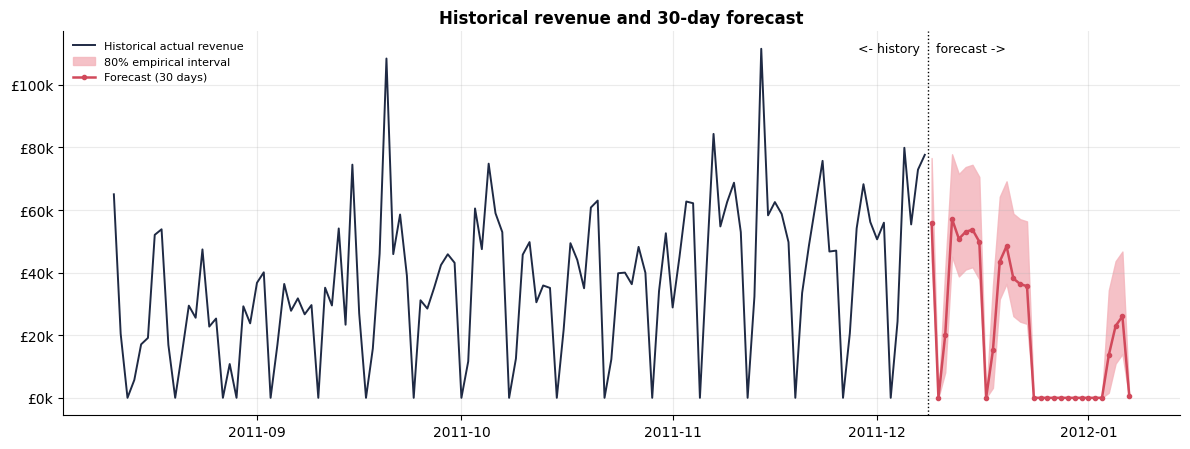

In [3]:
history = series.iloc[-120:]
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(history.index, history.values, color=plotting.COLORS["actual"], lw=1.4, label="Historical actual revenue")
ax.fill_between(saved.index, saved["lower"], saved["upper"], color=plotting.COLORS["interval"], alpha=0.85, label="80% empirical interval")
ax.plot(saved.index, saved["forecast"], color=plotting.COLORS["forecast"], lw=1.8, marker="o", ms=3, label="Forecast (30 days)")
split = series.index[-1] + pd.Timedelta(hours=12)
ax.axvline(split, color="black", ls=":", lw=1)
ax.text(split, ax.get_ylim()[1] * 0.97, "  forecast ->", va="top", fontsize=9)
ax.text(split, ax.get_ylim()[1] * 0.97, "<- history  ", va="top", ha="right", fontsize=9)
ax.yaxis.set_major_formatter(GBP)
ax.set_title("Historical revenue and 30-day forecast")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plotting.save_figure(fig, "fig18_forecast_30d.png")
plt.show()

In [4]:
table = saved.copy()
table.insert(0, "weekday", table.index.day_name())
table["closed_by_calendar"] = fe.known_closure_mask(table.index)
table.round(0)

,weekday,forecast,lower,upper,closed_by_calendar
date,,,,,
2011-12-09,Friday,"55,907.00","43,886.00","76,623.00",False
2011-12-10,Saturday,0.00,0.00,0.00,False
2011-12-11,Sunday,"20,155.00","8,133.00","40,871.00",False
2011-12-12,Monday,"57,115.00","45,093.00","77,831.00",False
2011-12-13,Tuesday,"50,812.00","38,790.00","71,528.00",False
2011-12-14,Wednesday,"53,029.00","41,008.00","73,745.00",False
2011-12-15,Thursday,"53,749.00","41,727.00","74,465.00",False
2011-12-16,Friday,"49,874.00","37,853.00","70,590.00",False
2011-12-17,Saturday,0.00,0.00,0.00,False


**How this forecast is produced.** The model predicts one day at a time. Each prediction becomes the "yesterday" and "last week" input for the following days (recursive strategy), so no real future value is ever used. Days that the calendar says are closed (UK holidays and 24 December - 3 January) are forecast as exactly zero, and the empirical interval collapses to zero for them.

**Why the band widens.** The interval is built from the model's out-of-sample validation errors, separately for open and closed-calendar days. It is an approximation, and uncertainty genuinely grows further out because later days depend on earlier *forecasts*, not observations.

## 2 · Business readout (computed from the saved forecast and the history)

In [5]:
f = saved["forecast"]
open_days = f[f > 0]
last_year = series.loc["2010-12-09":"2011-01-07"]
print(f"Forecast window total: GBP {f.sum():,.0f} over {len(f)} days ({len(open_days)} days with forecast revenue, {int((f == 0).sum())} zero days)")
print(f"Average forecast on days with revenue: GBP {open_days.mean():,.0f}")
print(f"Same calendar window one year earlier (actual): GBP {last_year.sum():,.0f}  -> forecast is {(f.sum() / last_year.sum() - 1) * 100:+.1f}% vs that")

growth = series.loc["2011-01-01":"2011-11-30"].sum() / series.loc["2010-01-01":"2010-11-30"].sum() - 1
print(f"For context, observed Jan-Nov 2011 revenue vs Jan-Nov 2010: {growth * 100:+.1f}%")

nov = series.loc["2011-11-01":"2011-11-30"]
print(f"\nObserved November 2011: GBP {nov.sum():,.0f}, average GBP {nov[nov > 0].mean():,.0f} per trading day")

mid_dec_fc = f.loc[:"2011-12-23"]
mid_dec_2010 = series.loc["2010-12-09":"2010-12-23"]
a, b = mid_dec_fc[mid_dec_fc > 0].mean(), mid_dec_2010[mid_dec_2010 > 0].mean()
print(f"9-23 December: forecast averages GBP {a:,.0f} per trading day vs GBP {b:,.0f} observed on the same dates in 2010 ({(a / b - 1) * 100:+.0f}%)")
sep_nov = series.loc["2011-09-01":"2011-11-30"].sum() / series.loc["2010-09-01":"2010-11-30"].sum() - 1
print(f"For comparison, observed Sep-Nov 2011 vs Sep-Nov 2010 revenue growth: {sep_nov * 100:+.1f}%")

after = f.loc["2012-01-04":"2012-01-06"]
prev_after = series.loc["2011-01-04":"2011-01-06"]
print(f"4-6 January 2012: forecast averages GBP {after.mean():,.0f} per day vs GBP {prev_after.mean():,.0f} observed on 4-6 January 2011")

Forecast window total: GBP 621,338 over 30 days (17 days with forecast revenue, 13 zero days)
Average forecast on days with revenue: GBP 36,549
Same calendar window one year earlier (actual): GBP 532,218  -> forecast is +16.7% vs that
For context, observed Jan-Nov 2011 revenue vs Jan-Nov 2010: +2.3%

Observed November 2011: GBP 1,451,114, average GBP 55,812 per trading day
9-23 December: forecast averages GBP 42,923 per trading day vs GBP 32,099 observed on the same dates in 2010 (+34%)
For comparison, observed Sep-Nov 2011 vs Sep-Nov 2010 revenue growth: +5.5%
4-6 January 2012: forecast averages GBP 20,879 per day vs GBP 29,091 observed on 4-6 January 2011


**Observed historical patterns**

* Revenue climbs from September to a November peak, is strong in early December, then stops completely over the year-end closure and restarts in January at a much lower level.
* The shop does not trade on Saturdays, on UK holidays, or from 24 December to 3 January.

**Model predictions (not guarantees)**

* The model eases revenue down from the November level through mid-December, forecasts exactly zero over the closure, and restarts in January at a lower level.
* The total for the 30-day window is a point estimate. It cannot be turned into a total interval by adding the daily bounds.

**Business interpretation (with caveats)**

* The *shape* (busy through about 23 December, closed afterwards, quieter restart) is the most dependable part of the forecast and can guide stock and staffing plans.
* **The pound level for mid-December looks optimistic.** The forecast for 9-23 December is far above what the same dates produced in 2010, a gap much larger than the recent year-on-year growth printed above. Plausible reasons (not tested here): the model has seen only **one** previous December, and its recursive forecast carries part of the very strong November level forward. Treat the December values as an upper-leaning estimate, compare them against actual sales as they arrive, and do not read the +% versus last year as expected growth.
* A forecast that is wrong in *level* but right in *shape* is still useful for scheduling, but not for hard financial targets.

## 3 · Where does the model miss? (final test period)

In [6]:
pred = pd.read_csv(config.TEST_PREDICTIONS_FILE, parse_dates=["date"]).set_index("date")
err = pred["actual"] - pred["forecast"]
pred["error"] = err
pred["weekday"] = pred.index.day_name()

print(f"Mean error (actual - forecast): GBP {err.mean():,.0f}  (positive = model under-forecasts on average)")
print(f"Days where actual > forecast: {int((err > 0).sum())} of {len(err)}")
open_mask = pred["actual"] > 0
print(f"MAE on open days: GBP {err[open_mask].abs().mean():,.0f} | on closed days: GBP {err[~open_mask].abs().mean():,.0f}")

by_day = pred.assign(abs_error=err.abs()).groupby("weekday")["abs_error"].agg(["count", "mean"]).round(0)
print("\nMean absolute error by weekday:"); print(by_day.to_string())

misses = pred.assign(abs_error=err.abs()).nlargest(5, "abs_error")[["weekday", "actual", "forecast", "error", "baseline_seasonal_naive", "baseline_seasonal_average_4w"]]
print("\nFive largest misses:"); print(misses.round(0).to_string())

Mean error (actual - forecast): GBP 2,201  (positive = model under-forecasts on average)
Days where actual > forecast: 14 of 30
MAE on open days: GBP 9,932 | on closed days: GBP 497

Mean absolute error by weekday:
           count      mean
weekday                   
Friday         4  3,097.00
Monday         4 20,604.00
Saturday       4    497.00
Sunday         4  6,073.00
Thursday       5  8,829.00
Tuesday        4 11,287.00
Wednesday      5  9,971.00

Five largest misses:
              weekday     actual  forecast     error  baseline_seasonal_naive  baseline_seasonal_average_4w
date                                                                                                       
2011-11-14     Monday 111,531.00 63,041.00 48,490.00                84,327.00                     56,533.00
2011-12-05     Monday  79,894.00 54,844.00 25,050.00                84,327.00                     56,533.00
2011-11-23  Wednesday  75,718.00 53,852.00 21,866.00                45,025.00           

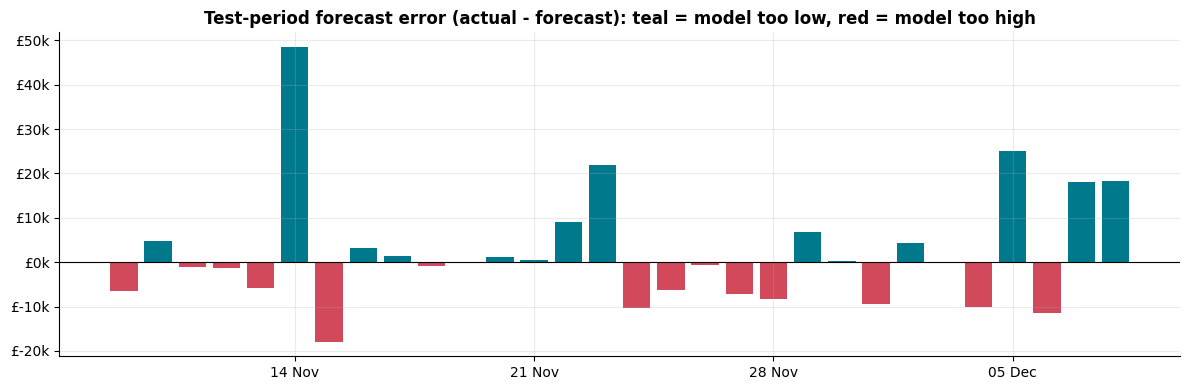

Largest actual day: 2011-11-14 (GBP 111,531); every method was below it: {'model': 63041, 'seasonal naive': 84327, 'seasonal avg 4w': 56533, 'naive': 54761, 'moving avg 7': 50230}


In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = [plotting.COLORS["forecast"] if v < 0 else plotting.COLORS["accent"] for v in pred["error"]]
ax.bar(pred.index, pred["error"], color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(GBP)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Test-period forecast error (actual - forecast): teal = model too low, red = model too high")
fig.tight_layout()
plotting.save_figure(fig, "fig19_test_residuals.png")
plt.show()

biggest = pred["actual"].idxmax()
row = pred.loc[biggest]
print(f"Largest actual day: {biggest.date()} (GBP {row['actual']:,.0f}); every method was below it:",
      {"model": round(row["forecast"]), "seasonal naive": round(row["baseline_seasonal_naive"]),
       "seasonal avg 4w": round(row["baseline_seasonal_average_4w"]), "naive": round(row["baseline_naive"]),
       "moving avg 7": round(row["baseline_moving_average_7"])})

**What the errors tell us.** The model tracks the weekday pattern and the closed Saturdays well (closed-day errors are small), and a large part of its error comes from **a few unusually strong trading days** (for example 14 November, far above every method's forecast). A model built on past revenue and the calendar cannot anticipate a one-off spike, and the data does not tell us *why* those days were so strong. Such days push RMSE up more than MAE.

**What would improve it.** Information about the *future* that the model cannot see: planned promotions, known large-customer orders, marketing calendar, or more years of history (so the Christmas peak is seen more than once). These are listed as future improvements in the README.